In [5]:
import pandas as pd
#Pandas have 2 datastructres - Dataframe and Series

df = pd.read_csv(r"C:\Users\gokul\OneDrive\Desktop\MCA\SEM 2\Python\Classworks\president_heights1.csv")
df.head()

,order,name,height(cm)
0,16,Abraham Lincoln,193.0
1,7,Andrew Jackson,185.0
2,17,Andrew Johnson,178.0
3,44,Barack Obama,NaN
4,23,Benjamin Harrison,168.0


In [ ]:
df.info()
#how to identify if there are null values?
#The first two values have 42 entries but the height column has only 37 entries

<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   order       42 non-null     int64  
 1   name        42 non-null     str    
 2   height(cm)  37 non-null     float64
dtypes: float64(1), int64(1), str(1)
memory usage: 1.7 KB


In [ ]:
df.describe()
#python will not consider non numberic values for summary statistics
#how many values are present it will give count for those values

,order,height(cm)
count,42.000000,37.000000
mean,22.476190,179.378378
std,13.152461,7.361127
min,1.000000,163.000000
25%,11.250000,173.000000
50%,22.000000,180.000000
75%,33.750000,183.000000
max,44.000000,193.000000


In [12]:
print(df.loc[0])
#Single row slection by label

order                      16
name          Abraham Lincoln
height(cm)              193.0
Name: 0, dtype: object


In [14]:
print(df.iloc[0:5])
#First five rows

   order               name  height(cm)
0     16    Abraham Lincoln       193.0
1      7     Andrew Jackson       185.0
2     17     Andrew Johnson       178.0
3     44       Barack Obama         NaN
4     23  Benjamin Harrison       168.0


In [13]:
print(df.iloc[0:5, 0:2])
#First 5 rows(0-4) and first two 2 columns(index 0 and 1)

   order               name
0     16    Abraham Lincoln
1      7     Andrew Jackson
2     17     Andrew Johnson
3     44       Barack Obama
4     23  Benjamin Harrison


In [ ]:
print(df.iloc[[0, 2, 9]])
#Specific non consecutive rows

   order                   name  height(cm)
0     16        Abraham Lincoln       193.0
2     17         Andrew Johnson       178.0
9     32  Franklin D. Roosevelt       188.0


In [ ]:
print(df.iloc[[0, 2, 4], [1, 2]])
#Specific non consecutive rows and columns

                name  height(cm)
0    Abraham Lincoln       193.0
2     Andrew Johnson       178.0
4  Benjamin Harrison       168.0


In [17]:
#Display every second row upto 20 rows
print(df.iloc[0:20:2])

    order                  name  height(cm)
0      16       Abraham Lincoln       193.0
2      17        Andrew Johnson       178.0
4      23     Benjamin Harrison       168.0
6      30       Calvin Coolidge       178.0
8      34  Dwight D. Eisenhower       179.0
10     14       Franklin Pierce         NaN
12     43        George W. Bush       182.0
14     38           Gerald Ford         NaN
16     31        Herbert Hoover       182.0
18     15        James Buchanan       183.0


In [ ]:
df1 = df.dropna()

df1['era'] = pd.cut(df1['order'], bins = [0, 15, 30, 45], labels = ['Early Era', 'Middle Era', 'Modern Era'])
df1.head()

,order,name,height(cm),era
0,16,Abraham Lincoln,193.0,Middle Era
1,7,Andrew Jackson,185.0,Early Era
2,17,Andrew Johnson,178.0,Middle Era
4,23,Benjamin Harrison,168.0,Middle Era
5,42,Bill Clinton,188.0,Modern Era


In [ ]:
df[df['height(cm)'].isnull()]
#select rows with missing height data

,order,name,height(cm)
3,44,Barack Obama,NaN
10,14,Franklin Pierce,NaN
14,38,Gerald Ford,NaN
17,20,James A. Garfield,NaN
24,35,John F. Kennedy,NaN


In [20]:
df[df['height(cm)'].notnull()]
#select rows with valid (non-null) height data

,order,name,height(cm)
0,16,Abraham Lincoln,193.0
1,7,Andrew Jackson,185.0
2,17,Andrew Johnson,178.0
4,23,Benjamin Harrison,168.0
5,42,Bill Clinton,188.0
6,30,Calvin Coolidge,178.0
7,21,Chester A. Arthur,183.0
8,34,Dwight D. Eisenhower,179.0
9,32,Franklin D. Roosevelt,188.0
11,41,George H. W. Bush,188.0


In [21]:
#Drop any rows containing missing data
clean_df = df.dropna()
print(df.shape)
print(clean_df.shape)

(42, 3)
(37, 3)


In [ ]:
#Forward fill - In place of null values the previous values will be filled
Ffill = df.ffill()
print(Ffill)

    order                    name  height(cm)
0      16         Abraham Lincoln       193.0
1       7          Andrew Jackson       185.0
2      17          Andrew Johnson       178.0
3      44            Barack Obama       178.0
4      23       Benjamin Harrison       168.0
5      42            Bill Clinton       188.0
6      30         Calvin Coolidge       178.0
7      21       Chester A. Arthur       183.0
8      34    Dwight D. Eisenhower       179.0
9      32   Franklin D. Roosevelt       188.0
10     14         Franklin Pierce       188.0
11     41       George H. W. Bush       188.0
12     43          George W. Bush       182.0
13      1       George Washington       189.0
14     38             Gerald Ford       189.0
15     33         Harry S. Truman       175.0
16     31          Herbert Hoover       182.0
17     20       James A. Garfield       182.0
18     15          James Buchanan       183.0
19     11           James K. Polk       173.0
20      4           James Madison 

In [ ]:
#Backward fill - In place of null values the previous values will be filled from backward
Bfill = df.bfill()
print(Bfill)

    order                    name  height(cm)
0      16         Abraham Lincoln       193.0
1       7          Andrew Jackson       185.0
2      17          Andrew Johnson       178.0
3      44            Barack Obama       168.0
4      23       Benjamin Harrison       168.0
5      42            Bill Clinton       188.0
6      30         Calvin Coolidge       178.0
7      21       Chester A. Arthur       183.0
8      34    Dwight D. Eisenhower       179.0
9      32   Franklin D. Roosevelt       188.0
10     14         Franklin Pierce       188.0
11     41       George H. W. Bush       188.0
12     43          George W. Bush       182.0
13      1       George Washington       189.0
14     38             Gerald Ford       175.0
15     33         Harry S. Truman       175.0
16     31          Herbert Hoover       182.0
17     20       James A. Garfield       183.0
18     15          James Buchanan       183.0
19     11           James K. Polk       173.0
20      4           James Madison 

In [28]:
early_tall = df[(df['height(cm)'] > 185) & (df['order'] <= 20)]
print(early_tall)

extremes = df[(df['height(cm)'] > 190) | (df['height(cm)'] > 165)]
print(extremes)

not_lincoln = df[~(df['name'] == 'Abraham Lincoln')]
print(not_lincoln)

    order               name  height(cm)
0      16    Abraham Lincoln       193.0
13      1  George Washington       189.0
34      3   Thomas Jefferson       189.0
    order                    name  height(cm)
0      16         Abraham Lincoln       193.0
1       7          Andrew Jackson       185.0
2      17          Andrew Johnson       178.0
4      23       Benjamin Harrison       168.0
5      42            Bill Clinton       188.0
6      30         Calvin Coolidge       178.0
7      21       Chester A. Arthur       183.0
8      34    Dwight D. Eisenhower       179.0
9      32   Franklin D. Roosevelt       188.0
11     41       George H. W. Bush       188.0
12     43          George W. Bush       182.0
13      1       George Washington       189.0
15     33         Harry S. Truman       175.0
16     31          Herbert Hoover       182.0
18     15          James Buchanan       183.0
19     11           James K. Polk       173.0
21      5            James Monroe       183.0
22     3

In [32]:
df[(df['height(cm)'] == df['height(cm)'].max())]

,order,name,height(cm)
0,16,Abraham Lincoln,193.0
27,36,Lyndon B. Johnson,193.0


In [34]:
top_5 = df.head(5)
print(top_5)

bottom_5 = df.tail(5)
print(bottom_5)

tallest_3 = df.nlargest(3, 'height(cm)')
print(tallest_3)

shortest_3 = df.nsmallest(3, 'height(cm)')
print(shortest_3)

   order               name  height(cm)
0     16    Abraham Lincoln       193.0
1      7     Andrew Jackson       185.0
2     17     Andrew Johnson       178.0
3     44       Barack Obama         NaN
4     23  Benjamin Harrison       168.0
    order                    name  height(cm)
37      9  William Henry Harrison       173.0
38     27     William Howard Taft       182.0
39     25        William McKinley       170.0
40     28          Woodrow Wilson       180.0
41     12          Zachary Taylor       173.0
    order               name  height(cm)
0      16    Abraham Lincoln       193.0
27     36  Lyndon B. Johnson       193.0
13      1  George Washington       189.0
    order               name  height(cm)
20      4      James Madison       163.0
4      23  Benjamin Harrison       168.0
28      8   Martin Van Buren       168.0


In [35]:
random_5 = df.sample(n = 5, random_state = 43)
print(random_5)

random_pct = df.sample(frac = 0.2, random_state = 41)
print(random_pct)

    order              name  height(cm)
14     38       Gerald Ford         NaN
6      30   Calvin Coolidge       178.0
5      42      Bill Clinton       188.0
39     25  William McKinley       170.0
26     10        John Tyler       183.0
    order                  name  height(cm)
30     37         Richard Nixon       182.0
41     12        Zachary Taylor       173.0
8      34  Dwight D. Eisenhower       179.0
33     26    Theodore Roosevelt       178.0
40     28        Woodrow Wilson       180.0
7      21     Chester A. Arthur       183.0
5      42          Bill Clinton       188.0
38     27   William Howard Taft       182.0


<Axes: title={'center': 'Top 5 Tallest Presidents'}, xlabel='order'>

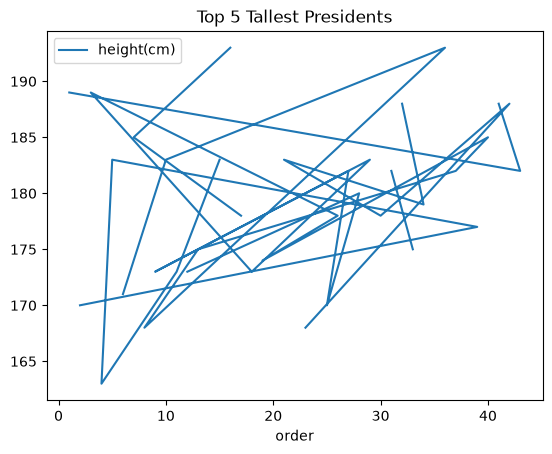

In [37]:
df.plot(x = 'order', y = 'height(cm)', title = 'Top 5 Tallest Presidents')

<Axes: title={'center': 'Top 5 Tallest Presidents'}, xlabel='name'>

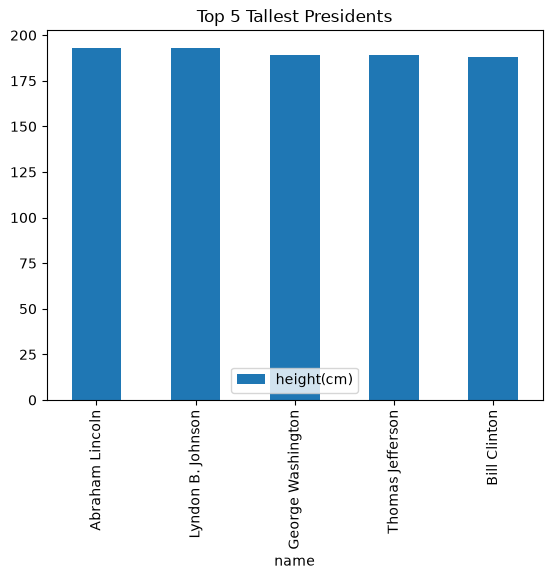

In [36]:
top5 = df.nlargest(5, 'height(cm)')
top5.plot.bar(x = 'name', y = 'height(cm)', title = 'Top 5 Tallest Presidents')

<Axes: title={'center': 'Height Distribution'}, ylabel='Frequency'>

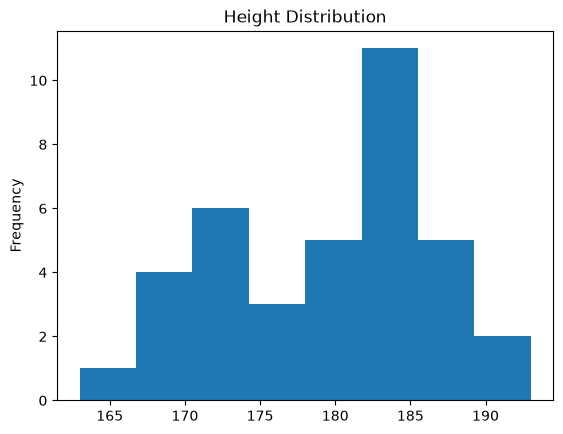

In [ ]:
#Histogram
df['height(cm)'].plot.hist(bins = 8, title = 'Height Distribution')
#bins = 8 means in 8 equal intervals it will divide

<Axes: >

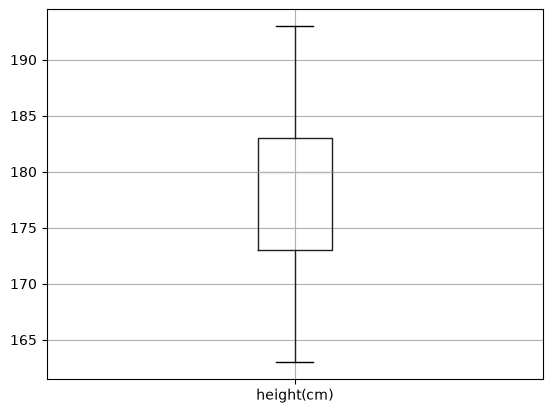

In [8]:
#Box Plot
df.boxplot(column = 'height(cm)')

<Axes: title={'center': 'Order vs Height'}, xlabel='order', ylabel='height(cm)'>

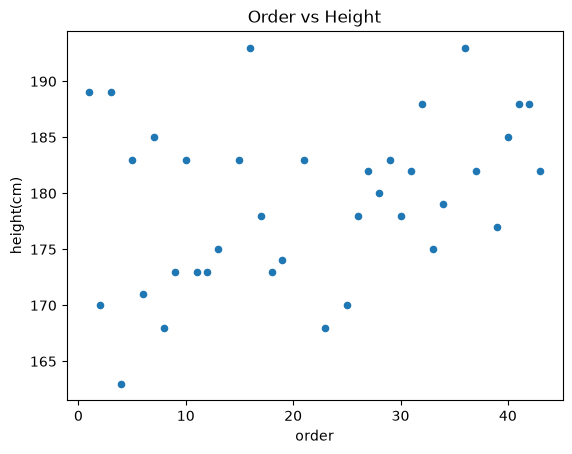

In [11]:
#Scatter Plot
df.plot.scatter(x='order', y='height(cm)', title = 'Order vs Height')

In [18]:
#Create Multiindex from existing columns
df_multi = df1.set_index(['era', 'name']).sort_index()
df_multi.head(20)

order  height(cm)
era        name                                     
Early Era  Andrew Jackson              7       185.0
           George Washington           1       189.0
           James Buchanan             15       183.0
           James K. Polk              11       173.0
           James Madison               4       163.0
           James Monroe                5       183.0
           John Adams                  2       170.0
           John Quincy Adams           6       171.0
           John Tyler                 10       183.0
           Martin Van Buren            8       168.0
           Millard Fillmore           13       175.0
           Thomas Jefferson            3       189.0
           William Henry Harrison      9       173.0
           Zachary Taylor             12       173.0
Middle Era Abraham Lincoln            16       193.0
           Andrew Johnson             17       178.0
           Benjamin Harrison          23       168.0
           Calvin Coolidge            30       178.0
           Chester A. Arthur          21       183.0
           Rutherford B. Hayes        19       174.0

In [20]:
#Select all presidents in the 'Early Era'
print(df_multi.loc['Early Era'])
print(df_multi.loc[('Early Era', 'George Washington')])

                        order  height(cm)
name                                     
Andrew Jackson              7       185.0
George Washington           1       189.0
James Buchanan             15       183.0
James K. Polk              11       173.0
James Madison               4       163.0
James Monroe                5       183.0
John Adams                  2       170.0
John Quincy Adams           6       171.0
John Tyler                 10       183.0
Martin Van Buren            8       168.0
Millard Fillmore           13       175.0
Thomas Jefferson            3       189.0
William Henry Harrison      9       173.0
Zachary Taylor             12       173.0
order           1.0
height(cm)    189.0
Name: (Early Era, George Washington), dtype: float64


In [22]:
#Calculate average height for each era level
era_means = df_multi.groupby(level = 'era', observed = False)['height(cm)'].mean()

print(era_means)

era
Early Era     177.000000
Middle Era    178.333333
Modern Era    183.545455
Name: height(cm), dtype: float64


In [23]:
#Presidents taller than 185 cm
tall_presidents = df[df['height(cm)'] > 185]
print(tall_presidents)

    order                   name  height(cm)
0      16        Abraham Lincoln       193.0
5      42           Bill Clinton       188.0
9      32  Franklin D. Roosevelt       188.0
11     41      George H. W. Bush       188.0
13      1      George Washington       189.0
27     36      Lyndon B. Johnson       193.0
34      3       Thomas Jefferson       189.0


In [29]:
#Create a data frame and pick only first four rows of the data and create a dataframe

first_four = df.dropna().head(4)
print(first_four)

   order               name  height(cm)
0     16    Abraham Lincoln       193.0
1      7     Andrew Jackson       185.0
2     17     Andrew Johnson       178.0
4     23  Benjamin Harrison       168.0


In [31]:
#Melt

melted = pd.melt(
    first_four,
    id_vars=['order', 'name'],
    var_name='metric',
    value_name='value'
)
print("------Melted------")
print(melted)

------Melted------
   order               name      metric  value
0     16    Abraham Lincoln  height(cm)  193.0
1      7     Andrew Jackson  height(cm)  185.0
2     17     Andrew Johnson  height(cm)  178.0
3     23  Benjamin Harrison  height(cm)  168.0


In [32]:
first_four['height_category'] = pd.cut(df['height(cm)'], bins = 3, labels = ['Short', ' Medium', 'Tail'])

pivot_tbl = first_four.pivot_table(
    index = 'height_category', values = 'height(cm)', aggfunc = ['mean', 'count', 'sum'], observed = False)
print(first_four)
print("------Pivot Table------")
print(pivot_tbl)

   order               name  height(cm) height_category
0     16    Abraham Lincoln       193.0            Tail
1      7     Andrew Jackson       185.0            Tail
2     17     Andrew Johnson       178.0          Medium
4     23  Benjamin Harrison       168.0           Short
------Pivot Table------
                      mean      count        sum
                height(cm) height(cm) height(cm)
height_category                                 
Short                168.0          1      168.0
 Medium              178.0          1      178.0
Tail                 189.0          2      378.0


In [33]:
#Set a multiindex
Reshaped_Index = first_four.set_index(['order', 'name'])

#Stack
stacked = Reshaped_Index.stack()

#Unstack
unstacked = stacked.unstack()

print("------Satcked Series------")
print(stacked.head(4))

------Satcked Series------
order  name                            
16     Abraham Lincoln  height(cm)         193.0
                        height_category     Tail
7      Andrew Jackson   height(cm)         185.0
                        height_category     Tail
dtype: object


In [34]:
first_four.T

,0,1,2,4
order,16,7,17,23
name,Abraham Lincoln,Andrew Jackson,Andrew Johnson,Benjamin Harrison
height(cm),193.0,185.0,178.0,168.0
height_category,Tail,Tail,Medium,Short
